PART 1: Window count comparison across all 26 subjects
Subject     Old Filter    New Filter      Diff      % Change
VP001             1023          1023        +0         +0.0%
VP002             1026          1026        +0         +0.0%
VP003             1026          1026        +0         +0.0%
VP004              752           929      +177        +23.5%
VP005             1016          1026       +10         +1.0%
VP006             1026          1026        +0         +0.0%
VP007             1026          1026        +0         +0.0%
VP008             1023          1023        +0         +0.0%
VP009             1024          1024        +0         +0.0%
VP010             1023          1023        +0         +0.0%
VP011             1023          1026        +3         +0.3%
VP012             1026          1026        +0         +0.0%
VP013             1023          1023        +0         +0.0%
VP014             1016          1016        +0         +0.0%
VP015             1010        

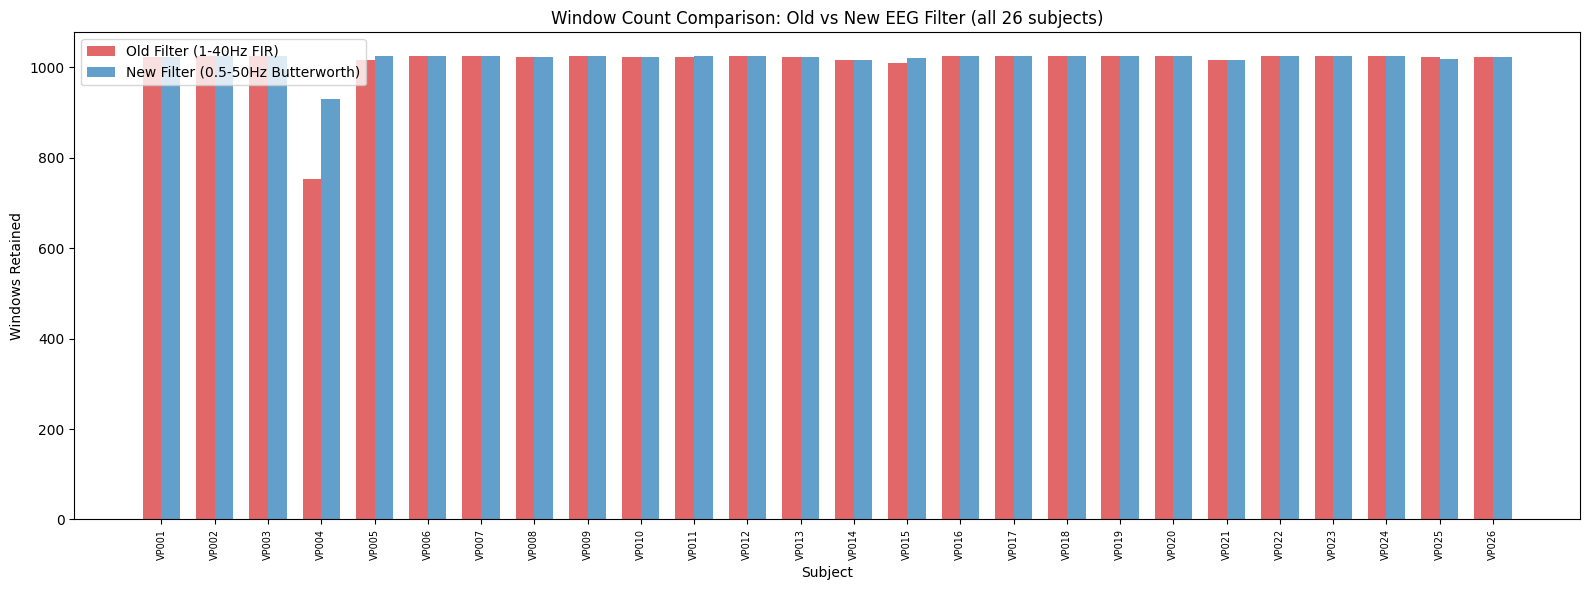

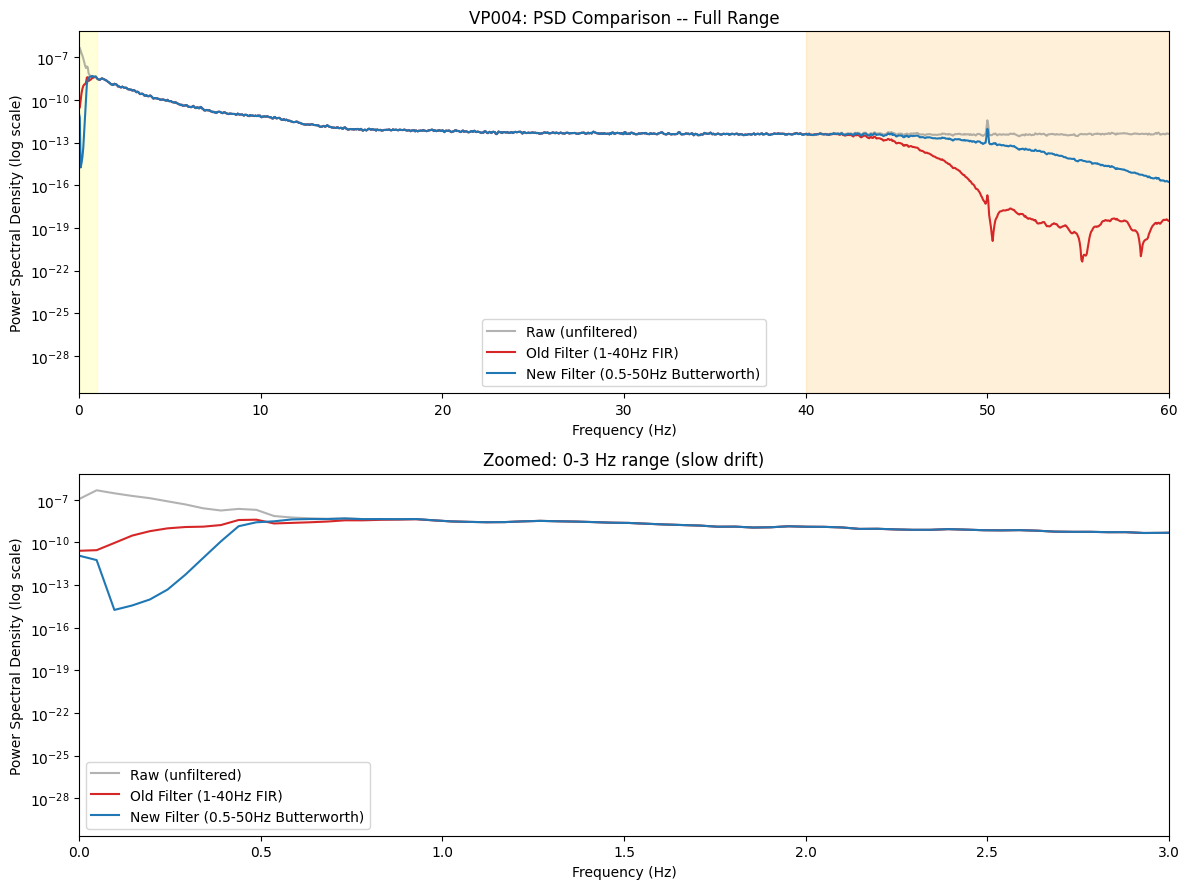

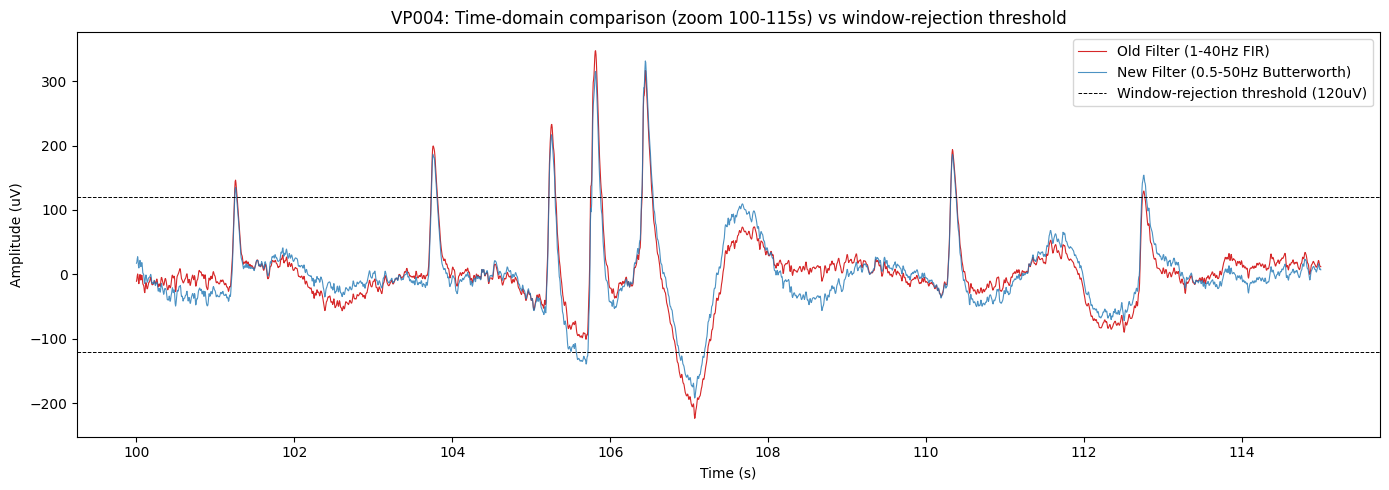

In [2]:
"""
Empirical comparison of two EEG filters: (1) 1-40Hz FIR (old) vs (2) 0.5-50Hz
6th-order zero-phase Butterworth (new, per TSFNet paper).

This script does three things:
  1. Quantitative comparison of window count retained per subject (table + bar chart)
  2. Direct PSD / time-domain comparison of both filters on real raw data from one
     subject -- to see, from evidence, which filter actually removes more noise,
     instead of guessing from filter parameters alone.
  3. A data-driven (not theoretical) conclusion about why the new filter might
     retain fewer/more artifact-rejected windows.

Prerequisite: both preprocessed versions (old filter and new filter) should exist
on disk, in two separate folders.
"""
import os
import numpy as np
import scipy.io as sio
import mne
import matplotlib.pyplot as plt
from scipy.signal import welch

# ============================== CONFIG -- set these two paths correctly ==============================
OLD_FILTER_PATH = r"F:\preprocessing-history-thesis\Preproc run h with baseline"   # output folder with 1-40Hz FIR filter
NEW_FILTER_PATH = r"F:\preprocessing-history-thesis\Preproc run h baseline eegfilter"              # output folder with 0.5-50Hz Butterworth filter
BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"  # for part 2 (raw data)

ALL_SUBJECTS = [f"VP{i:03d}" for i in range(1, 27)]


# ============================== PART 1: window count comparison ==============================
def get_window_count(base_path, subject):
    labels_file = os.path.join(base_path, subject, f"{subject}_labels.npy")
    if not os.path.exists(labels_file):
        return None
    return np.load(labels_file).shape[0]


print("=" * 90)
print("PART 1: Window count comparison across all 26 subjects")
print("=" * 90)
print(f"{'Subject':<8}{'Old Filter':>14}{'New Filter':>14}{'Diff':>10}{'% Change':>14}")

old_counts, new_counts, subjects_ok = [], [], []
for subject in ALL_SUBJECTS:
    n_old = get_window_count(OLD_FILTER_PATH, subject)
    n_new = get_window_count(NEW_FILTER_PATH, subject)
    if n_old is None or n_new is None:
        print(f"{subject:<8}{'--':>14}{'--':>14}{'(file not found)':>24}")
        continue
    diff = n_new - n_old
    pct = (diff / n_old * 100) if n_old > 0 else 0
    print(f"{subject:<8}{n_old:>14}{n_new:>14}{diff:>+10}{pct:>+13.1f}%")
    old_counts.append(n_old)
    new_counts.append(n_new)
    subjects_ok.append(subject)

old_counts = np.array(old_counts)
new_counts = np.array(new_counts)

print("\n" + "-" * 90)
print(f"Total windows: old={old_counts.sum()}  new={new_counts.sum()}  "
      f"change={new_counts.sum()-old_counts.sum():+d} ({(new_counts.sum()-old_counts.sum())/old_counts.sum()*100:+.2f}%)")
print(f"Mean per subject: old={old_counts.mean():.1f}  new={new_counts.mean():.1f}")
n_improved = (new_counts > old_counts).sum()
n_worse = (new_counts < old_counts).sum()
n_same = (new_counts == old_counts).sum()
print(f"Subjects where new filter kept MORE windows: {n_improved} / {len(subjects_ok)}")
print(f"Subjects where new filter kept FEWER windows: {n_worse} / {len(subjects_ok)}")
print(f"Subjects with no change: {n_same} / {len(subjects_ok)}")

# Bar chart comparison
if len(subjects_ok) > 0:
    fig, ax = plt.subplots(figsize=(16, 6))
    x = np.arange(len(subjects_ok))
    width = 0.35
    ax.bar(x - width/2, old_counts, width, label='Old Filter (1-40Hz FIR)', color='tab:red', alpha=0.7)
    ax.bar(x + width/2, new_counts, width, label='New Filter (0.5-50Hz Butterworth)', color='tab:blue', alpha=0.7)
    ax.set_xlabel('Subject')
    ax.set_ylabel('Windows Retained')
    ax.set_title('Window Count Comparison: Old vs New EEG Filter (all 26 subjects)')
    ax.set_xticks(x)
    ax.set_xticklabels(subjects_ok, rotation=90, fontsize=7)
    ax.legend()
    plt.tight_layout()
    plt.savefig("window_count_comparison.png", dpi=150)
    print("\nSaved chart: window_count_comparison.png")


# ============================== PART 2: direct PSD comparison on real raw data ==============================
print("\n" + "=" * 90)
print("PART 2: Direct PSD / time-domain comparison of both filters on real raw EEG")
print("=" * 90)

QC_SUBJECT = "VP004"  # the subject where the window-count difference was observed
eeg_folder = os.path.join(BASE_DATASET_PATH, f"{QC_SUBJECT}-EEG")
cnt_path = os.path.join(eeg_folder, "cnt_nback.mat")

mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)
cnt_struct = mat_cnt[[k for k in mat_cnt.keys() if not k.startswith('__')][0]]
data = cnt_struct.x.T
sfreq = float(cnt_struct.fs)
ch_names = [str(ch).strip() for ch in cnt_struct.clab]

if np.max(np.abs(data)) > 1.0:
    data = data * 1e-6

if sfreq != 200.0:
    from scipy.signal import resample
    n_samples = int(data.shape[1] * 200.0 / sfreq)
    data = resample(data, n_samples, axis=1)
    sfreq = 200.0

info = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types='eeg')
raw = mne.io.RawArray(data.copy(), info, verbose=False)
eog_channels = [ch for ch in ['VEOG', 'HEOG'] if ch in ch_names]
if eog_channels:
    raw.set_channel_types({ch: 'eog' for ch in eog_channels})

# Apply both filters independently to the SAME raw signal (no notch, to isolate just these two filters)
raw_old = raw.copy().filter(l_freq=1.0, h_freq=40.0, method='fir', verbose=False)
raw_new = raw.copy().filter(l_freq=0.5, h_freq=50.0, method='iir',
                             iir_params=dict(order=6, ftype='butter'), phase='zero', verbose=False)

qc_channel = 0
data_raw = raw.get_data(picks=[qc_channel])[0]
data_old = raw_old.get_data(picks=[qc_channel])[0]
data_new = raw_new.get_data(picks=[qc_channel])[0]

# --- PSD plot ---
freqs_raw, psd_raw = welch(data_raw, fs=sfreq, nperseg=4096)
freqs_old, psd_old = welch(data_old, fs=sfreq, nperseg=4096)
freqs_new, psd_new = welch(data_new, fs=sfreq, nperseg=4096)

fig, axes = plt.subplots(2, 1, figsize=(12, 9))
axes[0].semilogy(freqs_raw, psd_raw, label='Raw (unfiltered)', color='gray', alpha=0.6)
axes[0].semilogy(freqs_old, psd_old, label='Old Filter (1-40Hz FIR)', color='tab:red')
axes[0].semilogy(freqs_new, psd_new, label='New Filter (0.5-50Hz Butterworth)', color='tab:blue')
axes[0].set_xlim(0, 60)
axes[0].set_xlabel('Frequency (Hz)')
axes[0].set_ylabel('Power Spectral Density (log scale)')
axes[0].set_title(f'{QC_SUBJECT}: PSD Comparison -- Full Range')
axes[0].legend()
axes[0].axvspan(0, 1, color='yellow', alpha=0.15, label='Below 1Hz (drift)')
axes[0].axvspan(40, 60, color='orange', alpha=0.15, label='Above 40Hz (muscle)')

axes[1].semilogy(freqs_raw, psd_raw, label='Raw (unfiltered)', color='gray', alpha=0.6)
axes[1].semilogy(freqs_old, psd_old, label='Old Filter (1-40Hz FIR)', color='tab:red')
axes[1].semilogy(freqs_new, psd_new, label='New Filter (0.5-50Hz Butterworth)', color='tab:blue')
axes[1].set_xlim(0, 3)
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Power Spectral Density (log scale)')
axes[1].set_title('Zoomed: 0-3 Hz range (slow drift)')
axes[1].legend()

plt.tight_layout()
plt.savefig("psd_comparison.png", dpi=150)
print("Saved PSD chart: psd_comparison.png")

# --- Quantify power in key bands ---
def power_in_band(freqs, psd, lo, hi):
    mask = (freqs >= lo) & (freqs < hi)
    return psd[mask].sum()

print("\nPower in key frequency bands (relative to raw signal):")
for label, lo, hi in [("0-1Hz (slow drift)", 0, 1), ("40-60Hz (muscle/high-freq noise)", 40, 60), ("8-12Hz (alpha, useful signal)", 8, 12)]:
    p_raw = power_in_band(freqs_raw, psd_raw, lo, hi)
    p_old = power_in_band(freqs_old, psd_old, lo, hi)
    p_new = power_in_band(freqs_new, psd_new, lo, hi)
    print(f"  {label}: raw={p_raw:.3e}  old={p_old:.3e} ({p_old/p_raw*100:.1f}% remaining)  "
          f"new={p_new:.3e} ({p_new/p_raw*100:.1f}% remaining)")

# --- Time-domain plot, zoomed on a short window ---
t = np.arange(len(data_raw)) / sfreq
zoom_start, zoom_end = 100, 115  # seconds
mask = (t >= zoom_start) & (t <= zoom_end)

fig2, ax2 = plt.subplots(figsize=(14, 5))
ax2.plot(t[mask], data_old[mask]*1e6, label='Old Filter (1-40Hz FIR)', color='tab:red', linewidth=0.8)
ax2.plot(t[mask], data_new[mask]*1e6, label='New Filter (0.5-50Hz Butterworth)', color='tab:blue', linewidth=0.8, alpha=0.8)
ax2.axhline(120, color='black', linestyle='--', linewidth=0.7, label='Window-rejection threshold (120uV)')
ax2.axhline(-120, color='black', linestyle='--', linewidth=0.7)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Amplitude (uV)')
ax2.set_title(f'{QC_SUBJECT}: Time-domain comparison (zoom {zoom_start}-{zoom_end}s) vs window-rejection threshold')
ax2.legend()
plt.tight_layout()
plt.savefig("time_domain_comparison.png", dpi=150)
print("Saved time-domain chart: time_domain_comparison.png")

print("\n" + "=" * 90)
print("Data-driven conclusion (not a prior assumption):")
print("Look at the 'power in key bands' table above -- if the new filter retained a")
print("LOWER percentage of raw power in the 0-1Hz or 40-60Hz bands, it genuinely")
print("removed more noise there (despite having a nominally WIDER passband) -- this")
print("would most likely come from the FIR vs. zero-phase IIR Butterworth design")
print("difference, not from the raw edge-frequency numbers themselves.")
print("=" * 90)